In [1]:
# =====================================================
# EXPERIMENT 4
# EXTERNAL DATASET VALIDATION
# PART 1: TRAINING DATA PREPARATION + INTERNAL SPLIT
# =====================================================


import pandas as pd
import numpy as np


print("="*70)
print("EXPERIMENT 4")
print("EXTERNAL DATASET VALIDATION")
print("PART 1: TRAINING DATA PREPARATION")
print("="*70)



# =====================================================
# LOAD TON-IOT TRAINING DATA
# =====================================================


print("\nLoading TON-IoT Dataset")


train_dataset = pd.read_csv(

    "../data/train_test_network.csv"

)



print(

    "Original Dataset Shape:",

    train_dataset.shape

)




# =====================================================
# CLEAN DATASET
# =====================================================


print("\nCleaning Dataset")



train_dataset.replace(

    "-",

    "unknown",

    inplace=True

)



train_dataset.fillna(

    "unknown",

    inplace=True

)



print("Cleaning Completed")





# =====================================================
# DROP UNUSED FEATURES
# =====================================================


drop_columns = [

    "src_ip",

    "dst_ip",

    "src_port",

    "dst_port",

    "ssl_subject",

    "ssl_issuer",

    "http_user_agent",

    "label"

]



train_dataset.drop(

    columns=drop_columns,

    inplace=True,

    errors="ignore"

)



print("\nDataset Shape After Feature Removal")

print(

    train_dataset.shape

)





# =====================================================
# CLASS DISTRIBUTION
# =====================================================


print("\nClass Distribution")


print(

    train_dataset["type"].value_counts()

)





# =====================================================
# 90/10 INTERNAL VALIDATION SPLIT
# =====================================================


from sklearn.model_selection import train_test_split



print("\nCreating 90/10 Internal Validation Split")



train_data, internal_test_data = train_test_split(

    train_dataset,

    test_size=0.10,

    random_state=42,

    stratify=train_dataset["type"]

)



print(

    "Training Data Shape:",

    train_data.shape

)



print(

    "Internal Validation Shape:",

    internal_test_data.shape

)



print("\n")

print("="*70)

print("PART 1 COMPLETED")

print("="*70)

EXPERIMENT 4
EXTERNAL DATASET VALIDATION
PART 1: TRAINING DATA PREPARATION

Loading TON-IoT Dataset
Original Dataset Shape: (211043, 44)

Cleaning Dataset
Cleaning Completed

Dataset Shape After Feature Removal
(211043, 36)

Class Distribution
type
normal        50000
backdoor      20000
ddos          20000
dos           20000
injection     20000
password      20000
ransomware    20000
scanning      20000
xss           20000
mitm           1043
Name: count, dtype: int64

Creating 90/10 Internal Validation Split
Training Data Shape: (189938, 36)
Internal Validation Shape: (21105, 36)


PART 1 COMPLETED


In [2]:
# =====================================================
# EXPERIMENT 4
# PART 2: TRAINING DATA PREPROCESSING
# =====================================================


from sklearn.preprocessing import (

    OneHotEncoder,

    StandardScaler,

    LabelEncoder

)


from sklearn.compose import ColumnTransformer



print("="*70)

print("EXPERIMENT 4")

print("PART 2: TRAINING DATA PREPROCESSING")

print("="*70)





# =====================================================
# SEPARATE TRAINING FEATURES AND LABEL
# =====================================================


print("\nSeparating Training Features and Labels")



X_train = train_data.drop(

    "type",

    axis=1

)



y_train = train_data["type"]





# =====================================================
# INTERNAL VALIDATION DATA
# =====================================================


X_internal_test = internal_test_data.drop(

    "type",

    axis=1

)



y_internal_test = internal_test_data["type"]





print("\nTraining Features:")

print(X_train.shape)



print("\nInternal Validation Features:")

print(X_internal_test.shape)





# =====================================================
# LABEL ENCODING
# =====================================================


print("\nEncoding Labels")



label_encoder = LabelEncoder()



y_train_encoded = label_encoder.fit_transform(

    y_train

)



y_internal_test_encoded = label_encoder.transform(

    y_internal_test

)



print("\nClasses")

print(

    label_encoder.classes_

)






# =====================================================
# IDENTIFY FEATURE TYPES
# =====================================================


print("\nIdentifying Feature Types")



categorical_columns = X_train.select_dtypes(

    include="object"

).columns.tolist()



numerical_columns = X_train.select_dtypes(

    exclude="object"

).columns.tolist()



print(

    "Categorical Features:",

    len(categorical_columns)

)



print(

    "Numerical Features:",

    len(numerical_columns)

)





# =====================================================
# FIX DATA TYPES
# =====================================================


print("\nFixing Data Types")



for col in categorical_columns:


    X_train[col] = X_train[col].astype(str)

    X_internal_test[col] = X_internal_test[col].astype(str)





for col in numerical_columns:


    X_train[col] = pd.to_numeric(

        X_train[col],

        errors="coerce"

    )


    X_internal_test[col] = pd.to_numeric(

        X_internal_test[col],

        errors="coerce"

    )





X_train[numerical_columns] = (

    X_train[numerical_columns]

    .fillna(0)

)



X_internal_test[numerical_columns] = (

    X_internal_test[numerical_columns]

    .fillna(0)

)



print("Datatype Correction Completed")






# =====================================================
# BUILD PREPROCESSOR
# =====================================================


print("\nBuilding Preprocessor")



preprocessor = ColumnTransformer(

    transformers=[


        (

            "cat",

            OneHotEncoder(

                handle_unknown="ignore",

                sparse_output=False

            ),

            categorical_columns

        ),



        (

            "num",

            StandardScaler(),

            numerical_columns

        )

    ]

)





# =====================================================
# FIT ONLY ON TRAINING DATA
# =====================================================


print("\nFitting Preprocessor")



X_train_processed = preprocessor.fit_transform(

    X_train

)





# =====================================================
# TRANSFORM INTERNAL VALIDATION DATA
# =====================================================


X_internal_processed = preprocessor.transform(

    X_internal_test

)





print("\nProcessed Training Shape")

print(

    X_train_processed.shape

)



print("\nProcessed Internal Validation Shape")

print(

    X_internal_processed.shape

)





print("\n")

print("="*70)

print("PART 2 COMPLETED")

print("="*70)

EXPERIMENT 4
PART 2: TRAINING DATA PREPROCESSING

Separating Training Features and Labels

Training Features:
(189938, 35)

Internal Validation Features:
(21105, 35)

Encoding Labels

Classes
['backdoor' 'ddos' 'dos' 'injection' 'mitm' 'normal' 'password'
 'ransomware' 'scanning' 'xss']

Identifying Feature Types
Categorical Features: 21
Numerical Features: 14

Fixing Data Types
Datatype Correction Completed

Building Preprocessor

Fitting Preprocessor


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_14140\2207976838.py:145: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = X_train.select_dtypes(



Processed Training Shape
(189938, 897)

Processed Internal Validation Shape
(21105, 897)


PART 2 COMPLETED


In [3]:
# =====================================================
# EXPERIMENT 4
# PART 3: RANDOM FOREST TRAINING
# SAME HYPERPARAMETERS AS EXPERIMENT 3
# =====================================================

from sklearn.ensemble import RandomForestClassifier

print("="*70)
print("EXPERIMENT 4")
print("PART 3: RANDOM FOREST TRAINING")
print("="*70)

# =====================================================
# BUILD RANDOM FOREST MODEL
# =====================================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# =====================================================
# TRAIN RANDOM FOREST
# =====================================================

print("\nTraining Random Forest")

rf_model.fit(
    X_train_processed,
    y_train_encoded
)

print("\nRandom Forest Training Completed")

print("="*70)
print("PART 3 COMPLETED")
print("="*70)

EXPERIMENT 4
PART 3: RANDOM FOREST TRAINING

Training Random Forest

Random Forest Training Completed
PART 3 COMPLETED


In [4]:
# =====================================================
# EXPERIMENT 4
# PART 4: XGBOOST TRAINING
# SAME HYPERPARAMETERS AS EXPERIMENT 3
# =====================================================


from xgboost import XGBClassifier



print("="*70)

print("EXPERIMENT 4")

print("PART 4: XGBOOST TRAINING")

print("="*70)




# =====================================================
# BUILD XGBOOST MODEL
# =====================================================


xgb_model = XGBClassifier(

    n_estimators=200,

    learning_rate=0.1,

    random_state=42,

    n_jobs=-1,

    objective="multi:softprob",

    eval_metric="mlogloss"

)




# =====================================================
# TRAIN XGBOOST
# =====================================================


print("\nTraining XGBoost")



xgb_model.fit(

    X_train_processed,

    y_train_encoded

)



print("\nXGBoost Training Completed")



print("="*70)

print("PART 4 COMPLETED")

print("="*70)

EXPERIMENT 4
PART 4: XGBOOST TRAINING

Training XGBoost

XGBoost Training Completed
PART 4 COMPLETED


In [5]:
# =====================================================
# EXPERIMENT 4
# PART 5: INTERNAL VALIDATION ON UNSEEN DATA
# =====================================================


from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    classification_report

)



print("="*70)

print("EXPERIMENT 4")

print("PART 5: INTERNAL VALIDATION")

print("="*70)





# =====================================================
# RANDOM FOREST VALIDATION
# =====================================================


print("\n")

print("="*50)

print("RANDOM FOREST INTERNAL VALIDATION")

print("="*50)



rf_predictions = rf_model.predict(

    X_internal_processed

)



rf_accuracy = accuracy_score(

    y_internal_test_encoded,

    rf_predictions

)



rf_precision = precision_score(

    y_internal_test_encoded,

    rf_predictions,

    average="weighted",

    zero_division=0

)



rf_recall = recall_score(

    y_internal_test_encoded,

    rf_predictions,

    average="weighted",

    zero_division=0

)



rf_f1 = f1_score(

    y_internal_test_encoded,

    rf_predictions,

    average="weighted",

    zero_division=0

)



print("\nRandom Forest Results")

print("----------------------")

print("Accuracy :", rf_accuracy)

print("Precision:", rf_precision)

print("Recall   :", rf_recall)

print("F1 Score :", rf_f1)



print("\nClassification Report")

print(

    classification_report(

        y_internal_test_encoded,

        rf_predictions,

        target_names=label_encoder.classes_,

        zero_division=0

    )

)






# =====================================================
# XGBOOST VALIDATION
# =====================================================


print("\n")

print("="*50)

print("XGBOOST INTERNAL VALIDATION")

print("="*50)



xgb_predictions = xgb_model.predict(

    X_internal_processed

)



xgb_accuracy = accuracy_score(

    y_internal_test_encoded,

    xgb_predictions

)



xgb_precision = precision_score(

    y_internal_test_encoded,

    xgb_predictions,

    average="weighted",

    zero_division=0

)



xgb_recall = recall_score(

    y_internal_test_encoded,

    xgb_predictions,

    average="weighted",

    zero_division=0

)



xgb_f1 = f1_score(

    y_internal_test_encoded,

    xgb_predictions,

    average="weighted",

    zero_division=0

)



print("\nXGBoost Results")

print("----------------------")

print("Accuracy :", xgb_accuracy)

print("Precision:", xgb_precision)

print("Recall   :", xgb_recall)

print("F1 Score :", xgb_f1)



print("\nClassification Report")

print(

    classification_report(

        y_internal_test_encoded,

        xgb_predictions,

        target_names=label_encoder.classes_,

        zero_division=0

    )

)





print("\n")

print("="*70)

print("PART 5 COMPLETED")

print("="*70)

EXPERIMENT 4
PART 5: INTERNAL VALIDATION


RANDOM FOREST INTERNAL VALIDATION

Random Forest Results
----------------------
Accuracy : 0.979578298981284
Precision: 0.9801101471403991
Recall   : 0.979578298981284
F1 Score : 0.9796496860520771

Classification Report
              precision    recall  f1-score   support

    backdoor       1.00      1.00      1.00      2000
        ddos       0.99      0.98      0.98      2000
         dos       0.99      0.98      0.99      2000
   injection       0.97      0.97      0.97      2000
        mitm       0.74      0.82      0.78       105
      normal       1.00      1.00      1.00      5000
    password       0.99      0.98      0.98      2000
  ransomware       0.92      0.99      0.95      2000
    scanning       0.98      0.99      0.99      2000
         xss       0.96      0.92      0.94      2000

    accuracy                           0.98     21105
   macro avg       0.95      0.96      0.96     21105
weighted avg       0.98      0.9

EXPERIMENT 4
CONFUSION MATRIX HEATMAPS - INTERNAL VALIDATION

Random Forest Confusion Matrix:
[[1998    0    0    0    0    2    0    0    0    0]
 [   0 1951    0   17    0    3    0   20    0    9]
 [   0    1 1960    0   14    0    4    0   21    0]
 [   0   10    0 1948    2    0    0    4    9   27]
 [   0    0    5    4   86    4    5    0    1    0]
 [   1    1    6    1    4 4983    1    1    1    1]
 [   0    0    1    1    7    0 1952   31    1    7]
 [   0    0    0    0    0    0    0 1972    0   28]
 [   0    0    5    1    2    0    2    0 1990    0]
 [   0    9    0   30    1    1    4  121    0 1834]]


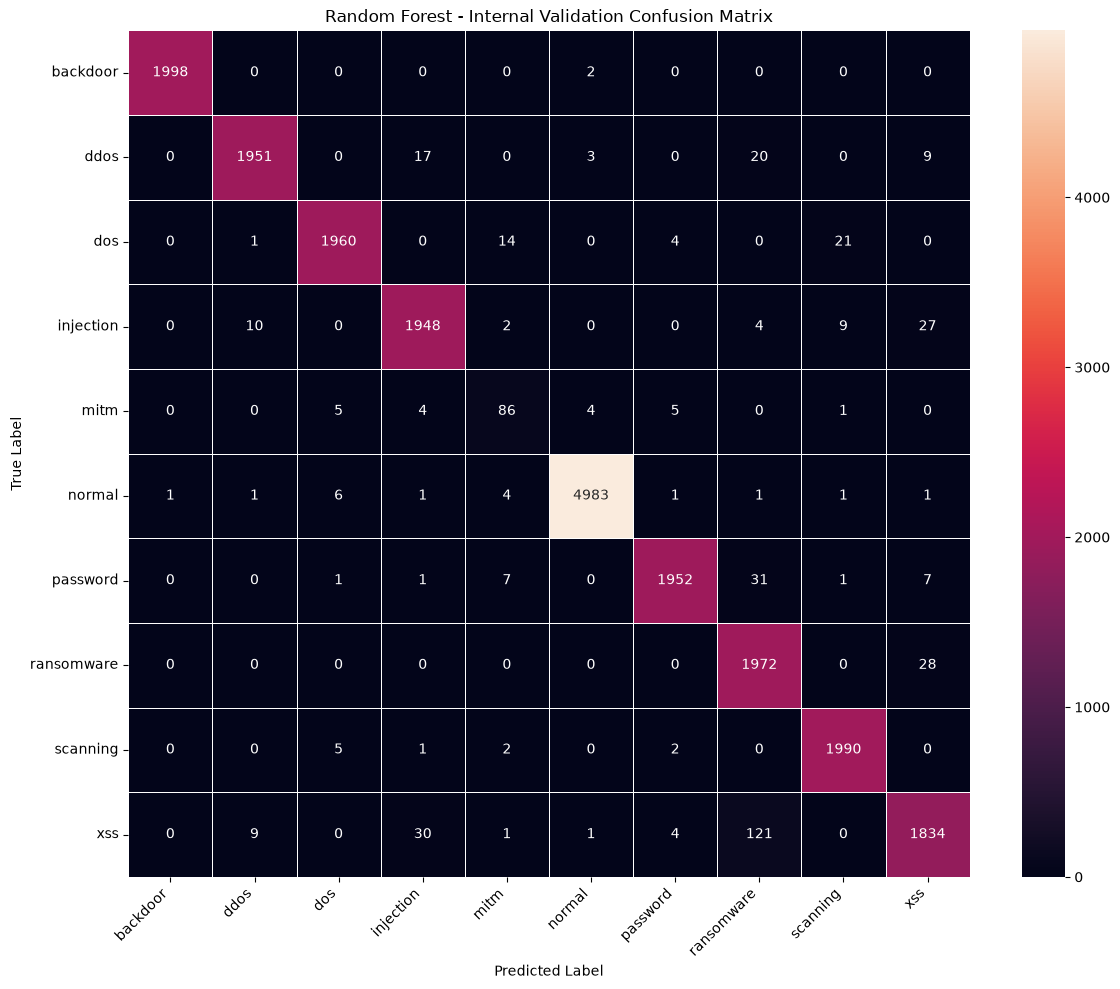


XGBoost Confusion Matrix:
[[1998    0    0    0    0    2    0    0    0    0]
 [   0 1949    0   12    1    2    0   20    0   16]
 [   0    0 1950    0   18    4    4    0   24    0]
 [   0   12    1 1939    1    2    0    3    9   33]
 [   0    0    4    3   89    8    0    0    1    0]
 [   0    3    3    0    5 4982    1    1    2    3]
 [   0    1    1    1    9    0 1947   31    4    6]
 [   0    0    0    0    0    0    0 1972    0   28]
 [   0    0    4    0    9    0    0    0 1987    0]
 [   0    3    0   16    0    1    0  121    0 1859]]


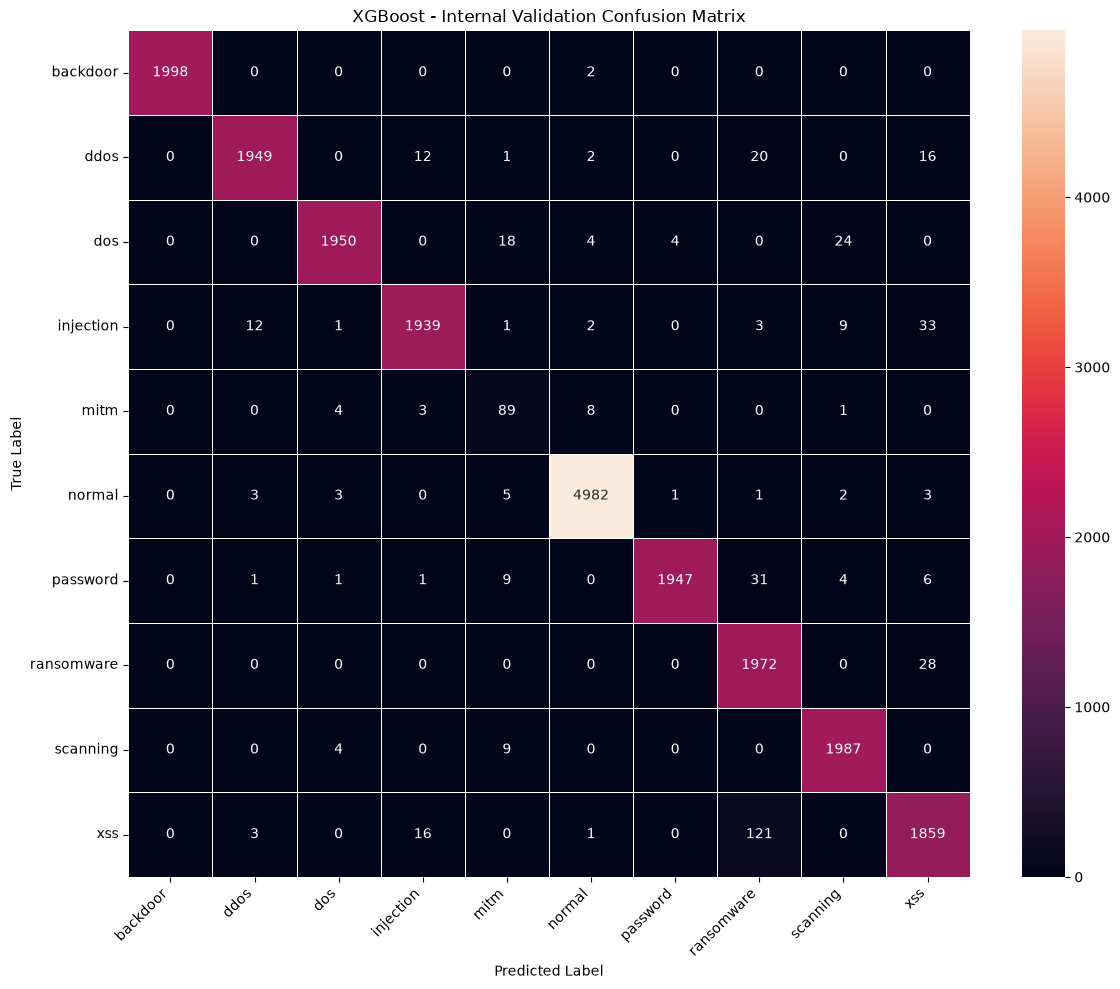



CONFUSION MATRIX HEATMAPS COMPLETED


In [6]:
# =====================================================
# EXPERIMENT 4
# PART 5.1: CONFUSION MATRIX HEATMAPS
# INTERNAL VALIDATION
# =====================================================

from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


print("="*70)
print("EXPERIMENT 4")
print("CONFUSION MATRIX HEATMAPS - INTERNAL VALIDATION")
print("="*70)


# =====================================================
# GET CLASS LABELS
# =====================================================

class_labels = label_encoder.classes_


# =====================================================
# RANDOM FOREST CONFUSION MATRIX
# =====================================================

rf_cm = confusion_matrix(

    y_internal_test_encoded,

    rf_predictions,

    labels=np.arange(
        len(class_labels)
    )

)


print("\nRandom Forest Confusion Matrix:")

print(rf_cm)


# =====================================================
# RANDOM FOREST HEATMAP
# =====================================================

plt.figure(

    figsize=(12, 10)

)


sns.heatmap(

    rf_cm,

    annot=True,

    fmt="d",

    xticklabels=class_labels,

    yticklabels=class_labels,

    linewidths=0.5

)


plt.xlabel(

    "Predicted Label"

)


plt.ylabel(

    "True Label"

)


plt.title(

    "Random Forest - Internal Validation Confusion Matrix"

)


plt.xticks(

    rotation=45,

    ha="right"

)


plt.yticks(

    rotation=0

)


plt.tight_layout()


plt.show()



# =====================================================
# XGBOOST CONFUSION MATRIX
# =====================================================

xgb_cm = confusion_matrix(

    y_internal_test_encoded,

    xgb_predictions,

    labels=np.arange(
        len(class_labels)
    )

)


print("\nXGBoost Confusion Matrix:")

print(xgb_cm)


# =====================================================
# XGBOOST HEATMAP
# =====================================================

plt.figure(

    figsize=(12, 10)

)


sns.heatmap(

    xgb_cm,

    annot=True,

    fmt="d",

    xticklabels=class_labels,

    yticklabels=class_labels,

    linewidths=0.5

)


plt.xlabel(

    "Predicted Label"

)


plt.ylabel(

    "True Label"

)


plt.title(

    "XGBoost - Internal Validation Confusion Matrix"

)


plt.xticks(

    rotation=45,

    ha="right"

)


plt.yticks(

    rotation=0

)


plt.tight_layout()


plt.show()



print("\n")
print("="*70)
print("CONFUSION MATRIX HEATMAPS COMPLETED")
print("="*70)

In [7]:
# =====================================================
# EXPERIMENT 4
# PART 5: LOADING EXTERNAL DATASET
# =====================================================


print("="*70)

print("EXPERIMENT 4")

print("PART 5: LOADING EXTERNAL DATASET")

print("="*70)




# =====================================================
# LOAD EXTERNAL DATASETS
# =====================================================


print("\nLoading External Dataset")



dataset_1 = pd.read_csv(

    "../ids/Network_dataset_1.csv"

)



dataset_10 = pd.read_csv(

    "../ids/Network_dataset_10.csv"

)




print("\nDataset 1 Shape")

print(

    dataset_1.shape

)



print("\nDataset 10 Shape")

print(

    dataset_10.shape

)





# =====================================================
# COMBINE DATASETS
# =====================================================


external_dataset = pd.concat(

    [

        # dataset_1,

        dataset_10

    ],

    axis=0,

    ignore_index=True

)




print("\nCombined External Dataset Shape")

print(

    external_dataset.shape

)





# =====================================================
# CLEAN EXTERNAL DATASET
# SAME AS TRAINING DATA
# =====================================================


print("\nCleaning External Dataset")



external_dataset.replace(

    "-",

    "unknown",

    inplace=True

)



external_dataset.fillna(

    "unknown",

    inplace=True

)



print("Cleaning Completed")





# =====================================================
# CLASS DISTRIBUTION
# =====================================================


print("\nExternal Dataset Class Distribution")



print(

    external_dataset["type"].value_counts()

)



print("\n")

print("="*70)

print("PART 5 COMPLETED")

print("="*70)

EXPERIMENT 4
PART 5: LOADING EXTERNAL DATASET

Loading External Dataset


C:\Users\Kruthik Raj M\AppData\Local\Temp\ipykernel_14140\108649102.py:27: DtypeWarning: Columns (0: src_bytes) have mixed types. Specify dtype option on import or set low_memory=False.
  dataset_1 = pd.read_csv(



Dataset 1 Shape
(1000000, 46)

Dataset 10 Shape
(1000000, 46)

Combined External Dataset Shape
(1000000, 46)

Cleaning External Dataset
Cleaning Completed

External Dataset Class Distribution
type
dos       969998
normal     30002
Name: count, dtype: int64


PART 5 COMPLETED


In [8]:
# =====================================================
# EXPERIMENT 4
# PART 6: EXTERNAL DATASET PREPROCESSING
# FEATURE ALIGNMENT AND TRANSFORMATION
# =====================================================


print("="*70)

print("EXPERIMENT 4")

print("PART 6: EXTERNAL DATASET PREPROCESSING")

print("="*70)




# =====================================================
# REMOVE NON-USED FEATURES
# =====================================================


print("\nRemoving Unused Features")



# remove timestamp if available

external_dataset.drop(

    columns=["ts"],

    inplace=True,

    errors="ignore"

)



# remove same features removed from training

external_dataset.drop(

    columns=drop_columns,

    inplace=True,

    errors="ignore"

)



print(

    "Shape After Feature Removal:",

    external_dataset.shape

)





# =====================================================
# KEEP ONLY TRAINING CLASSES
# =====================================================


print("\nFiltering Unknown Classes")



external_dataset = external_dataset[

    external_dataset["type"].isin(

        label_encoder.classes_

    )

]



print("\nExternal Classes After Filtering")


print(

    external_dataset["type"].value_counts()

)





# =====================================================
# SPLIT FEATURES AND LABEL
# =====================================================


X_external = external_dataset.drop(

    "type",

    axis=1

)



y_external = external_dataset["type"]





# Encode external labels using training encoder

y_external_encoded = label_encoder.transform(

    y_external

)



print("\nExternal Feature Shape Before Alignment")

print(

    X_external.shape

)





# =====================================================
# FEATURE ALIGNMENT
# SAME FEATURE SPACE AS TRAINING
# =====================================================


print("\nAligning External Features")



missing_features = []



for col in X_train.columns:


    if col not in X_external.columns:


        missing_features.append(col)



        # categorical missing feature

        if col in categorical_columns:


            X_external[col] = "unknown"



        # numerical missing feature

        elif col in numerical_columns:


            X_external[col] = 0





print(

    "Missing Features Added:",

    len(missing_features)

)



if len(missing_features) > 0:


    print("\nAdded Features:")

    print(missing_features)





# reorder columns exactly like training


X_external = X_external[

    X_train.columns

]



print(

    "\nFeature Shape After Alignment"

)


print(

    X_external.shape

)





# =====================================================
# FIX DATA TYPES
# =====================================================


print("\nFixing Data Types")



# categorical columns

for col in categorical_columns:


    X_external[col] = (

        X_external[col]

        .astype(str)

    )




# numerical columns

for col in numerical_columns:


    X_external[col] = pd.to_numeric(

        X_external[col],

        errors="coerce"

    )





X_external[numerical_columns] = (

    X_external[numerical_columns]

    .fillna(0)

)



print(

    "Datatype Correction Completed"

)





# =====================================================
# APPLY TRAINED PREPROCESSOR
# NO FITTING
# =====================================================


print("\nTransforming External Dataset")



X_external_processed = preprocessor.transform(

    X_external

)




print(

    "Processed External Shape:",

    X_external_processed.shape

)



print(

    "Training Processed Shape:",

    X_train_processed.shape

)




print("\n")

print("="*70)

print("PART 6 COMPLETED")

print("="*70)

EXPERIMENT 4
PART 6: EXTERNAL DATASET PREPROCESSING

Removing Unused Features
Shape After Feature Removal: (1000000, 37)

Filtering Unknown Classes

External Classes After Filtering
type
dos       969998
normal     30002
Name: count, dtype: int64

External Feature Shape Before Alignment
(1000000, 36)

Aligning External Features
Missing Features Added: 0

Feature Shape After Alignment
(1000000, 35)

Fixing Data Types
Datatype Correction Completed

Transforming External Dataset
Processed External Shape: (1000000, 897)
Training Processed Shape: (189938, 897)


PART 6 COMPLETED


In [9]:
# =====================================================
# EXPERIMENT 4
# PART 7: RANDOM FOREST EXTERNAL VALIDATION
# =====================================================


from sklearn.metrics import (

    accuracy_score,

    precision_score,

    recall_score,

    f1_score,

    classification_report,

    confusion_matrix

)


import matplotlib.pyplot as plt

import seaborn as sns



print("="*70)

print("EXPERIMENT 4")

print("PART 7: RANDOM FOREST EXTERNAL VALIDATION")

print("="*70)





# =====================================================
# PREDICTION
# =====================================================


print("\nGenerating Random Forest Predictions")



rf_predictions1 = rf_model.predict(

    X_external_processed

)





# =====================================================
# PERFORMANCE METRICS
# =====================================================


accuracy = accuracy_score(

    y_external_encoded,

    rf_predictions1

)



precision = precision_score(

    y_external_encoded,

    rf_predictions1,

    average="weighted",

    zero_division=0

)



recall = recall_score(

    y_external_encoded,

    rf_predictions1,

    average="weighted",

    zero_division=0

)



f1 = f1_score(

    y_external_encoded,

    rf_predictions1,

    average="weighted",

    zero_division=0

)





print("\n")

print("="*70)

print("RANDOM FOREST EXTERNAL VALIDATION RESULTS")

print("="*70)



print(

    f"Accuracy  : {accuracy:.4f}"

)



print(

    f"Precision : {precision:.4f}"

)



print(

    f"Recall    : {recall:.4f}"

)



print(

    f"F1 Score  : {f1:.4f}"

)





# =====================================================
# CLASSIFICATION REPORT
# ALL TRAINING CLASSES
# =====================================================


print("\n")

print("="*70)

print("CLASSIFICATION REPORT")

print("="*70)



print(

    classification_report(

        y_external_encoded,

        rf_predictions1,

        labels=np.arange(

            len(label_encoder.classes_)

        ),

        target_names=label_encoder.classes_,

        digits=4,

        zero_division=0

    )

)





# =====================================================
# CONFUSION MATRIX
# =====================================================


# print("\n")

# print("="*70)

# print("CONFUSION MATRIX")

# print("="*70)



cm = confusion_matrix(

    y_external_encoded,

    rf_predictions1,

    labels=np.arange(

        len(label_encoder.classes_)

    )

)



# print(cm)





# # =====================================================
# # VISUALIZATION
# # =====================================================


# plt.figure(

#     figsize=(10,8)

# )



# sns.heatmap(

#     cm,

#     annot=True,

#     fmt="d",

#     xticklabels=label_encoder.classes_,

#     yticklabels=label_encoder.classes_

# )



# plt.xlabel(

#     "Predicted"

# )


# plt.ylabel(

#     "Actual"

# )


# plt.title(

#     "Random Forest External Validation Confusion Matrix"

# )



# plt.show()





print("\n")

print("="*70)

print("PART 7 COMPLETED")

print("="*70)

EXPERIMENT 4
PART 7: RANDOM FOREST EXTERNAL VALIDATION

Generating Random Forest Predictions


RANDOM FOREST EXTERNAL VALIDATION RESULTS
Accuracy  : 0.9956
Precision : 0.9999
Recall    : 0.9956
F1 Score  : 0.9977


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    backdoor     0.0000    0.0000    0.0000         0
        ddos     0.0000    0.0000    0.0000         0
         dos     1.0000    0.9975    0.9988    969998
   injection     0.0000    0.0000    0.0000         0
        mitm     0.0000    0.0000    0.0000         0
      normal     0.9988    0.9312    0.9638     30002
    password     0.0000    0.0000    0.0000         0
  ransomware     0.0000    0.0000    0.0000         0
    scanning     0.0000    0.0000    0.0000         0
         xss     0.0000    0.0000    0.0000         0

    accuracy                         0.9956   1000000
   macro avg     0.1999    0.1929    0.1963   1000000
weighted avg     0.9999    0.9956    0.9977   1000000



PA

In [10]:
# =====================================================
# TP TN FP FN TABLE (RF EXTERNAL VALIDATION)
# ONLY CLASSES PRESENT IN EXTERNAL DATASET
# =====================================================


print("\n")
print("="*70)
print("RANDOM FOREST TP TN FP FN TABLE")
print("="*70)



# Use existing confusion matrix
rf_cm = cm



# Calculate TP, FP, FN, TN

tp = np.diag(rf_cm)


fp = rf_cm.sum(axis=0) - tp


fn = rf_cm.sum(axis=1) - tp


tn = rf_cm.sum() - (tp + fp + fn)




# Create dataframe

rf_tpfptntable = pd.DataFrame({

    "Class": label_encoder.classes_,

    "TP": tp,

    "TN": tn,

    "FP": fp,

    "FN": fn,

    "Support": rf_cm.sum(axis=1)

})




# Remove classes with zero samples
rf_tpfptntable = rf_tpfptntable[
    rf_tpfptntable["Support"] > 0
]




print(
    rf_tpfptntable.to_string(index=False)
)






print("\nTP TN FP FN table saved successfully")



RANDOM FOREST TP TN FP FN TABLE
 Class     TP     TN  FP   FN  Support
   dos 967613  29985  17 2385   969998
normal  27939 969965  33 2063    30002

TP TN FP FN table saved successfully


In [11]:
# =====================================================
# EXPERIMENT 4
# PART 8: XGBOOST EXTERNAL VALIDATION
# =====================================================


print("="*70)

print("EXPERIMENT 4")

print("PART 8: XGBOOST EXTERNAL VALIDATION")

print("="*70)




# =====================================================
# GENERATE PREDICTIONS
# =====================================================


print("\nGenerating XGBoost Predictions")



xgb_predictions1 = xgb_model.predict(

    X_external_processed

)





# =====================================================
# PERFORMANCE METRICS
# =====================================================


xgb_accuracy = accuracy_score(

    y_external_encoded,

    xgb_predictions1

)



xgb_precision = precision_score(

    y_external_encoded,

    xgb_predictions1,

    average="weighted",

    zero_division=0

)



xgb_recall = recall_score(

    y_external_encoded,

    xgb_predictions1,

    average="weighted",

    zero_division=0

)



xgb_f1 = f1_score(

    y_external_encoded,

    xgb_predictions1,

    average="weighted",

    zero_division=0

)





print("\n")

print("="*70)

print("XGBOOST EXTERNAL VALIDATION RESULTS")

print("="*70)



print(

    f"Accuracy  : {xgb_accuracy:.4f}"

)



print(

    f"Precision : {xgb_precision:.4f}"

)



print(

    f"Recall    : {xgb_recall:.4f}"

)



print(

    f"F1 Score  : {xgb_f1:.4f}"

)





# =====================================================
# CLASSIFICATION REPORT
# =====================================================


print("\n")

print("="*70)

print("CLASSIFICATION REPORT")

print("="*70)



print(

    classification_report(

        y_external_encoded,

        xgb_predictions1,

        labels=np.arange(

            len(label_encoder.classes_)

        ),

        target_names=label_encoder.classes_,

        digits=4,

        zero_division=0

    )

)





# =====================================================
# CONFUSION MATRIX
# =====================================================


# print("\n")

# print("="*70)

# print("CONFUSION MATRIX")

# print("="*70)



xgb_cm = confusion_matrix(

    y_external_encoded,

    xgb_predictions1,

    labels=np.arange(

        len(label_encoder.classes_)

    )

)



# print(xgb_cm)





# # =====================================================
# # VISUALIZATION
# # =====================================================


# plt.figure(

#     figsize=(10,8)

# )



# sns.heatmap(

#     xgb_cm,

#     annot=True,

#     fmt="d",

#     xticklabels=label_encoder.classes_,

#     yticklabels=label_encoder.classes_

# )



# plt.xlabel(

#     "Predicted"

# )



# plt.ylabel(

#     "Actual"

# )



# plt.title(

#     "XGBoost External Validation Confusion Matrix"

# )



# plt.show()





print("\n")

print("="*70)

print("PART 8 COMPLETED")

print("="*70)





print("\n")

print("="*70)

print("EXPERIMENT 4 COMPLETED")

print("EXTERNAL DATASET VALIDATION FINISHED")

print("="*70)

EXPERIMENT 4
PART 8: XGBOOST EXTERNAL VALIDATION

Generating XGBoost Predictions


XGBOOST EXTERNAL VALIDATION RESULTS
Accuracy  : 0.9789
Precision : 0.9889
Recall    : 0.9789
F1 Score  : 0.9830


CLASSIFICATION REPORT
              precision    recall  f1-score   support

    backdoor     0.0000    0.0000    0.0000         0
        ddos     0.0000    0.0000    0.0000         0
         dos     1.0000    0.9808    0.9903    969998
   injection     0.0000    0.0000    0.0000         0
        mitm     0.0000    0.0000    0.0000         0
      normal     0.6300    0.9155    0.7464     30002
    password     0.0000    0.0000    0.0000         0
  ransomware     0.0000    0.0000    0.0000         0
    scanning     0.0000    0.0000    0.0000         0
         xss     0.0000    0.0000    0.0000         0

    accuracy                         0.9789   1000000
   macro avg     0.1630    0.1896    0.1737   1000000
weighted avg     0.9889    0.9789    0.9830   1000000



PART 8 COMPLETED


E

In [12]:
# =====================================================
# TP TN FP FN TABLE (ONLY CLASSES PRESENT IN DATASET)
# =====================================================

print("\n")
print("="*70)
print("TP TN FP FN TABLE")
print("="*70)


# Confusion matrix
cm1 = xgb_cm


# Calculate TP, FP, FN, TN
tp = np.diag(cm1)

fp = cm1.sum(axis=0) - tp

fn = cm1.sum(axis=1) - tp

tn = cm1.sum() - (tp + fp + fn)



# Create table
tp_tn_fn_fp_table = pd.DataFrame({

    "Class": label_encoder.classes_,

    "TP": tp,

    "TN": tn,

    "FP": fp,

    "FN": fn

})


# Add support column
tp_tn_fn_fp_table["Support"] = cm1.sum(axis=1)



# Keep only classes available in external dataset
tp_tn_fn_fp_table = tp_tn_fn_fp_table[
    tp_tn_fn_fp_table["Support"] > 0
]



print(tp_tn_fn_fp_table.to_string(index=False))



print("\nTP TN FP FN table saved successfully")



TP TN FP FN TABLE
 Class     TP     TN    FP    FN  Support
   dos 951403  29967    35 18595   969998
normal  27468 953865 16133  2534    30002

TP TN FP FN table saved successfully
